# 01 - Data Exploration
### AutoValue AI - Used Car Price Prediction | Yash Rajput - 2427010652

Understand the CarDekho `Car details v3.csv` data before training anything: structure, data quality,
the price distribution, and how the input fields relate to `selling_price`.

In [1]:
import os, sys, warnings
sys.path.insert(0, os.path.abspath(".."))
os.environ.setdefault("OMP_NUM_THREADS", "1")
os.environ.setdefault("LOKY_MAX_CPU_COUNT", "4")
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt

In [2]:
from src.preprocessing import load_raw, clean, INPUT_FIELDS, TARGET, FIGURES_DIR

raw = load_raw()
print("shape:", raw.shape)
raw.head()

shape: (8128, 13)


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.4 kmpl,1248 CC,74 bhp,190Nm@ 2000rpm,5.0
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14 kmpl,1498 CC,103.52 bhp,250Nm@ 1500-2500rpm,5.0
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.7 kmpl,1497 CC,78 bhp,"12.7@ 2,700(kgm@ rpm)",5.0
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.0 kmpl,1396 CC,90 bhp,22.4 kgm at 1750-2750rpm,5.0
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.1 kmpl,1298 CC,88.2 bhp,"11.5@ 4,500(kgm@ rpm)",5.0


## Data types, missing values and duplicates

In [3]:
print(raw.dtypes, "\n")
print("Missing values in the 7 input fields + target:")
print(raw[INPUT_FIELDS + [TARGET]].isnull().sum())
print("\nExact duplicate rows (all 13 columns):", raw.duplicated().sum())
print("Duplicate rows on the 8 modelled columns:", raw[INPUT_FIELDS + [TARGET]].duplicated().sum())

name              object
year               int64
selling_price      int64
km_driven          int64
fuel              object
seller_type       object
transmission      object
owner             object
mileage           object
engine            object
max_power         object
torque            object
seats            float64
dtype: object 

Missing values in the 7 input fields + target:
name             0
year             0
km_driven        0
fuel             0
seller_type      0
transmission     0
owner            0
selling_price    0
dtype: int64

Exact duplicate rows (all 13 columns): 1202
Duplicate rows on the 8 modelled columns: 1203


The 7 input fields and the target have **no missing values** (missing values exist only in the
optional spec columns - mileage, engine, power, torque, seats - which v1 does not use).
About 15% of rows are **exact duplicates**; they are removed before the train/test split so the same
car cannot appear in both sets.

## Unusual values

In [4]:
print("owner categories:", raw["owner"].value_counts().to_dict())
print("km_driven max:", f"{raw['km_driven'].max():,}", "| rows above 10 lakh km:",
      (raw["km_driven"] > 1_000_000).sum())
print("year range:", raw["year"].min(), "-", raw["year"].max())

owner categories: {'First Owner': 5289, 'Second Owner': 2105, 'Third Owner': 555, 'Fourth & Above Owner': 174, 'Test Drive Car': 5}
km_driven max: 2,360,457 | rows above 10 lakh km: 2
year range: 1983 - 2020


- **5 "Test Drive Car" rows** don't fit the previous-owner categories -> excluded and documented.
- **2 odometer readings above 10 lakh km** (max 23.6 lakh km) are implausible -> treated as errors.
- The data ends in **2020**, so the app can only support manufacturing years inside that range and
  its estimates are historical, not current-market valuations.

In [5]:
df, report = clean(raw)
report

{'raw_rows': 8128,
 'exact_duplicates_removed': 1203,
 'test_drive_rows_removed': 5,
 'invalid_rows_removed': 2,
 'clean_rows': 6918}

## Chart 1 - Selling price distribution

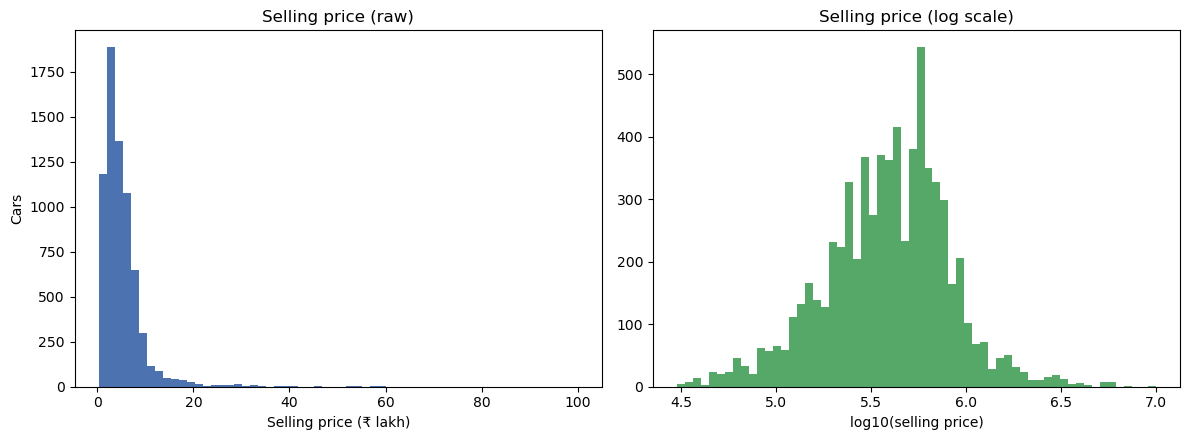

skewness raw: 5.44 | log: -0.17


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].hist(df["selling_price"] / 1e5, bins=60, color="#4C72B0")
axes[0].set_xlabel("Selling price (₹ lakh)"); axes[0].set_ylabel("Cars")
axes[0].set_title("Selling price (raw)")
axes[1].hist(np.log10(df["selling_price"]), bins=60, color="#55A868")
axes[1].set_xlabel("log10(selling price)"); axes[1].set_title("Selling price (log scale)")
fig.tight_layout(); fig.savefig(FIGURES_DIR / "eda_price_distribution.png", dpi=130); plt.show()
print("skewness raw:", round(df["selling_price"].skew(), 2),
      "| log:", round(np.log(df["selling_price"]).skew(), 2))

Prices are strongly right-skewed (a few very expensive cars, skewness ≈ 5.4). On a log scale the
distribution is close to symmetric, which is why the models are trained on log(price).

## Chart 2 - Manufacturing year vs price

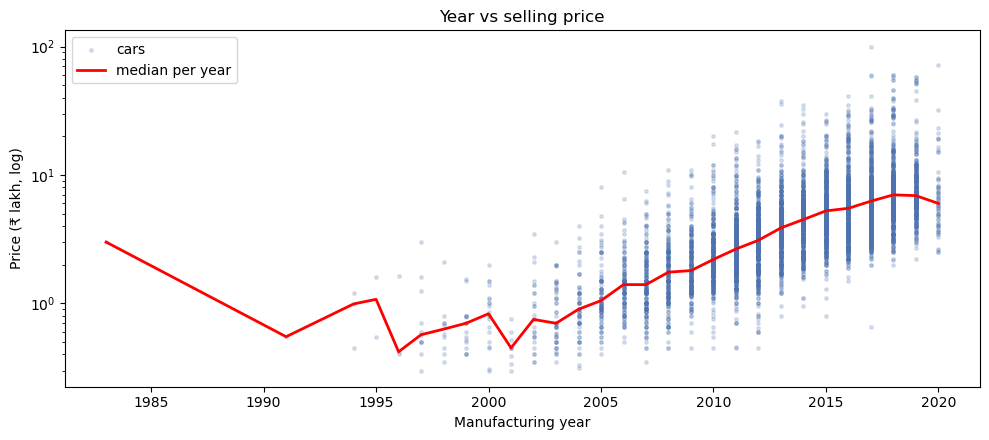

corr(year, log price): 0.719


In [7]:
med = df.groupby("year")["selling_price"].median() / 1e5
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.scatter(df["year"], df["selling_price"] / 1e5, s=6, alpha=0.2, color="#4C72B0", label="cars")
ax.plot(med.index, med.values, color="red", lw=2, label="median per year")
ax.set_yscale("log"); ax.set_xlabel("Manufacturing year"); ax.set_ylabel("Price (₹ lakh, log)")
ax.set_title("Year vs selling price"); ax.legend()
fig.tight_layout(); fig.savefig(FIGURES_DIR / "eda_year_vs_price.png", dpi=130); plt.show()
print("corr(year, log price):", round(df["year"].corr(np.log(df["selling_price"])), 3))

## Chart 3 - Kilometres driven vs price

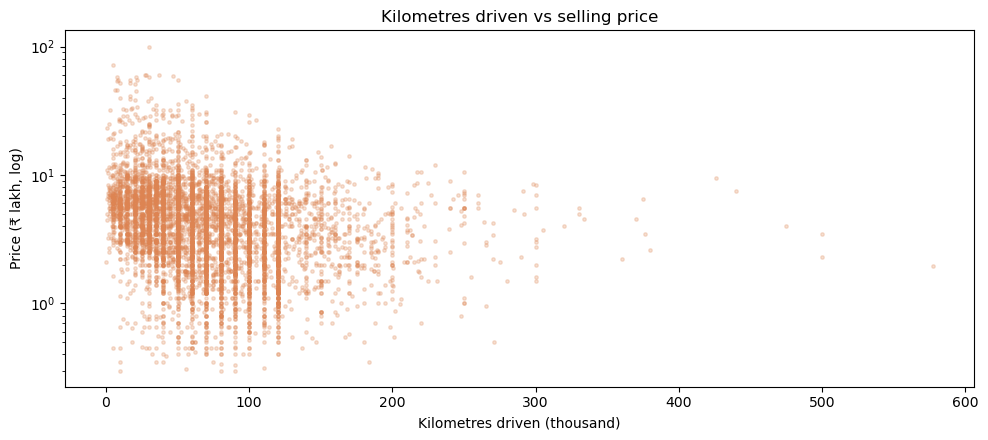

corr(km, log price): -0.229 | corr(year, km): -0.44


In [8]:
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.scatter(df["km_driven"] / 1000, df["selling_price"] / 1e5, s=6, alpha=0.25, color="#DD8452")
ax.set_yscale("log"); ax.set_xlabel("Kilometres driven (thousand)")
ax.set_ylabel("Price (₹ lakh, log)"); ax.set_title("Kilometres driven vs selling price")
fig.tight_layout(); fig.savefig(FIGURES_DIR / "eda_km_vs_price.png", dpi=130); plt.show()
print("corr(km, log price):", round(df["km_driven"].corr(np.log(df["selling_price"])), 3),
      "| corr(year, km):", round(df["year"].corr(df["km_driven"]), 3))

## Charts 4 & 5 - Median price by fuel, transmission and seller type

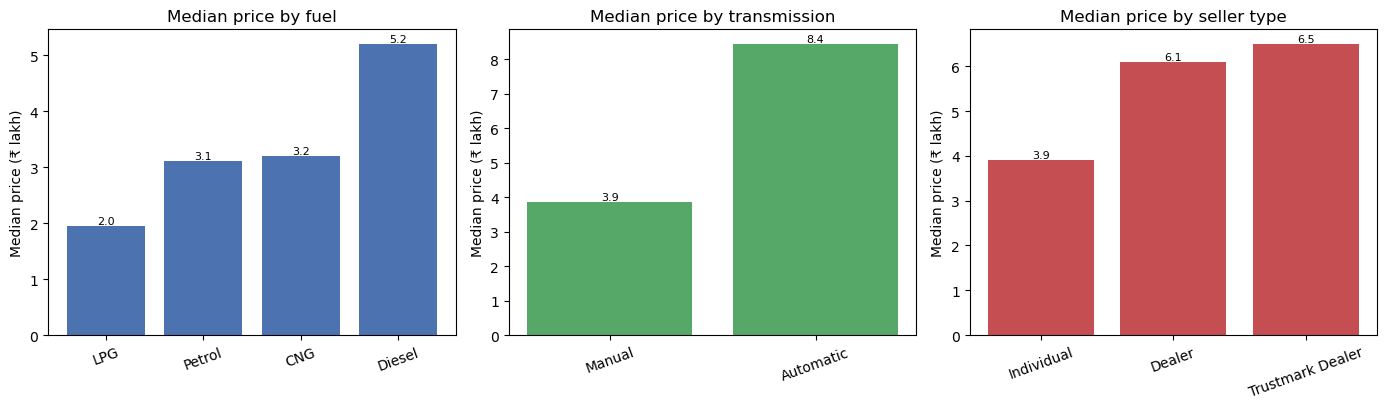

fuel {'Diesel': 3752, 'Petrol': 3072, 'CNG': 56, 'LPG': 38}
transmission {'Manual': 6338, 'Automatic': 580}
seller_type {'Individual': 6216, 'Dealer': 675, 'Trustmark Dealer': 27}
owner {'First Owner': 4240, 'Second Owner': 1973, 'Third Owner': 536, 'Fourth & Above Owner': 169}


In [9]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
for ax, col, color in zip(axes, ["fuel", "transmission", "seller_type"],
                          ["#4C72B0", "#55A868", "#C44E52"]):
    s = (df.groupby(col)["selling_price"].median() / 1e5).sort_values()
    ax.bar(s.index, s.values, color=color)
    ax.set_title(f"Median price by {col.replace('_', ' ')}")
    ax.set_ylabel("Median price (₹ lakh)"); ax.tick_params(axis="x", rotation=20)
    for i, v in enumerate(s.values):
        ax.text(i, v, f"{v:.1f}", ha="center", va="bottom", fontsize=8)
fig.tight_layout(); fig.savefig(FIGURES_DIR / "eda_category_prices.png", dpi=130); plt.show()
for col in ["fuel", "transmission", "seller_type", "owner"]:
    print(col, df[col].value_counts().to_dict())

## Findings
1. **Newer cars sell for more** - year has the strongest numeric association with log price
   (correlation ≈ 0.72).
2. **Kilometres driven** has a weaker negative association (≈ −0.23), and is itself correlated with
   age (older cars have driven more), so its separate effect is smaller.
3. **Automatic** cars have a much higher median price (≈ ₹8.5L) than manual (≈ ₹3.9L); **diesel**
   cars are pricier than petrol; **dealer** listings are higher than individual sellers.
4. Some categories are small (CNG 56, LPG 38, Trustmark Dealer 27 rows), so estimates for them rest on
   few examples.
5. These are associations in historical listings, **not causal effects** - e.g. automatic cars are
   also more often premium models.